**Лабораторна робота № 5 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

**Виконав:** Харченко Артьом, група ФІТ 3-10

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [2]:
# Використовуємо спосіб 2 (Kaggle), тому тут нічого не завантажуємо
# uploaded = files.upload()

In [3]:
# df = pd.read_csv('diabetes_prediction_dataset.csv')
# df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [5]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


У датасеті 100000 записів і 9 стовпців. gender і smoking_history текстові (object), решта числові. hypertension, heart_disease і diabetes записані як 0 або 1. Пропусків немає.

Провести дослідження категоріальних ознак

In [7]:
df["gender"].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


In [8]:
df["smoking_history"].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [9]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [10]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [11]:
df["diabetes"].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

**Відповідь:** так, є сильний дисбаланс класів. Класу 0 (немає діабету) 91500 записів, а класу 1 тільки 8500, тобто 8,5%.

Перевірити наявність пропущених даних


In [12]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [13]:
print("Дублікатів:", df.duplicated().sum())

Дублікатів: 3854


Видалити дублікати

In [14]:
df.drop_duplicates(inplace=True)

In [15]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [16]:
df["diabetes"].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


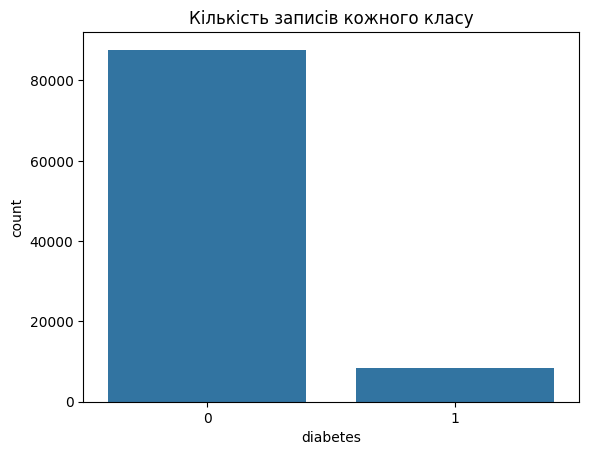

Частка класу 1: 8.82 %


In [17]:
sns.countplot(x="diabetes", data=df, color="tab:blue")
plt.title("Кількість записів кожного класу")
plt.show()

print("Частка класу 1:", round(df["diabetes"].mean() * 100, 2), "%")

Переглянути описові статистики **навчальної вибірки**

In [18]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [19]:
X = df.drop(columns="diabetes")
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Частка класу 1 у train:", round(y_train.mean() * 100, 2), "%, у test:", round(y_test.mean() * 100, 2), "%")

Train: (76916, 8) | Test: (19230, 8)
Частка класу 1 у train: 8.82 %, у test: 8.82 %


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [20]:
cat_cols = ["gender", "smoking_history"]

X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)

# у test мають бути ті самі стовпці, що й у train
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Стовпці:", X_train.columns.tolist())
print("Однакові стовпці в train і test:", list(X_train.columns) == list(X_test.columns))

Стовпці: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Female', 'gender_Male', 'gender_Other', 'smoking_history_No Info', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']
Однакові стовпці в train і test: True


In [21]:
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [22]:
X_train.corrwith(y_train).sort_values(ascending=False)

,0
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_former,0.096162
gender_Male,0.040650
smoking_history_never,0.025725
smoking_history_ever,0.020899


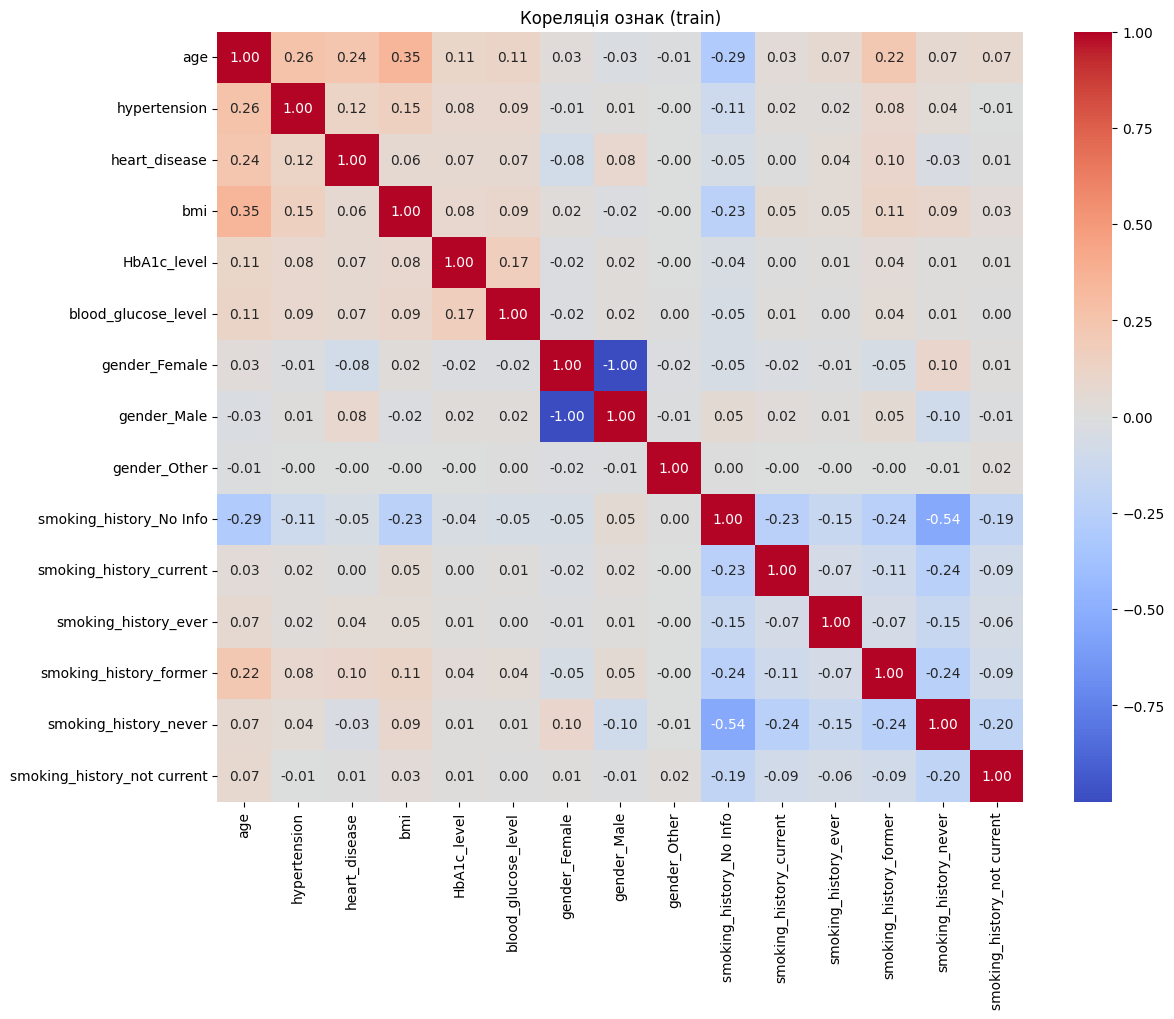

In [23]:
corr = X_train.corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Кореляція ознак (train)")
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

**Відповідь:** з цільовою змінною найсильніше корелюють blood_glucose_level (0.42) і HbA1c_level (0.41), далі age (0.27), bmi (0.21), hypertension (0.20) і heart_disease (0.17).

Між числовими ознаками сильних зв'язків немає, найбільша кореляція між age і bmi (0.35). Сильно корелюють тільки стовпці, які вийшли з однієї ознаки після get_dummies, наприклад gender_Female і gender_Male (-1), бо це по суті одна ознака. Тому ознаки не видаляємо.

Перевірити викиди **лише на навчальній вибірці**

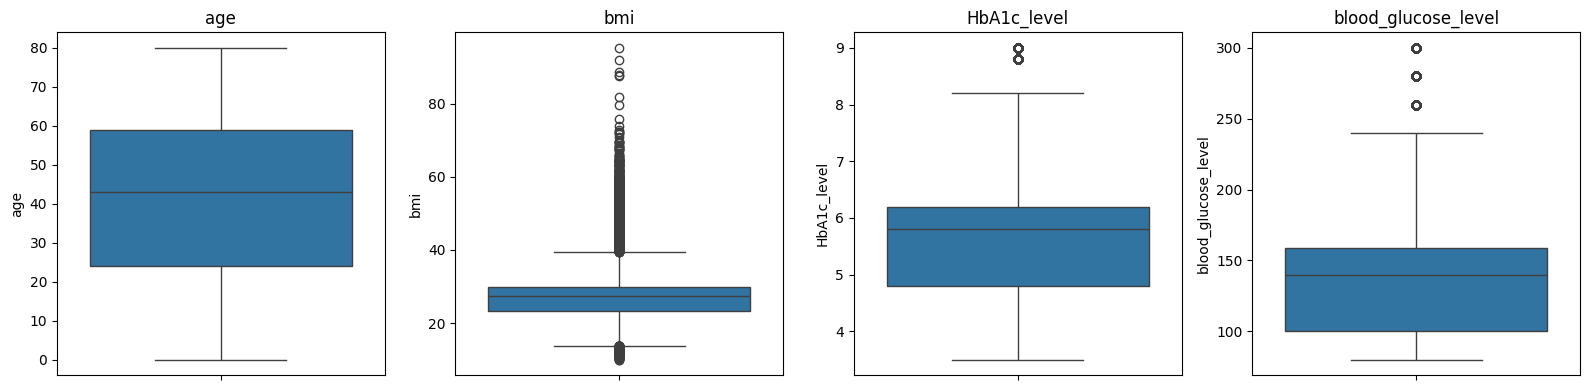

Значень за межами IQR у train:
age                       0
bmi                    4244
HbA1c_level            1041
blood_glucose_level    1598
dtype: int64


In [24]:
continuous_cols = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# скільки значень виходить за межі IQR (тільки рахуємо, не видаляємо)
q1 = X_train[continuous_cols].quantile(0.25)
q3 = X_train[continuous_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((X_train[continuous_cols] < q1 - 1.5 * iqr) | (X_train[continuous_cols] > q3 + 1.5 * iqr)).sum()
print("Значень за межами IQR у train:")
print(outliers)

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

За межами IQR у train найбільше значень у bmi (4244), blood_glucose_level (1598) і HbA1c_level (1041), в age таких немає. Ці значення залишаємо.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [25]:
# Приклад (не запускаємо, викиди в цій роботі не видаляємо):
# q1 = X_train["bmi"].quantile(0.25)
# q3 = X_train["bmi"].quantile(0.75)
# iqr = q3 - q1
# mask = (X_train["bmi"] >= q1 - 1.5 * iqr) & (X_train["bmi"] <= q3 + 1.5 * iqr)
# X_train = X_train[mask]
# y_train = y_train[mask]

Перевірити асиметрію розподілів ознак **на train**

In [26]:
X_train[continuous_cols].skew()

,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [27]:
print("Пропуски в X_train:", X_train.isna().sum().sum())
print("Пропуски в X_test:", X_test.isna().sum().sum())

Пропуски в X_train: 0
Пропуски в X_test: 0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Класи сильно незбалансовані: після видалення дублікатів класу 1 тільки 8,8%, тому навчальну вибірку будемо балансувати через SMOTE. З діабетом найбільше пов'язані рівень глюкози і HbA1c. Викиди є в bmi, глюкозі і HbA1c, але ми їх не видаляємо. Помітна асиметрія тільки в bmi (1.0) і глюкозі (0.83). Пропусків немає ні в train, ні в test.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [28]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [29]:
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print("До SMOTE:")
print(y_train.value_counts())
print()
print("Після SMOTE:")
print(pd.Series(y_train_bal).value_counts())

До SMOTE:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Після SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [30]:
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=42),
    "RidgeClassifier": RidgeClassifier(random_state=42),
    "SGDClassifier": SGDClassifier(random_state=42),
    "SVC": SVC(random_state=42),
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


==================== LogisticRegression ====================
              precision    recall  f1-score   support

           0      0.987     0.885     0.933     17534
           1      0.426     0.879     0.574      1696

    accuracy                          0.885     19230
   macro avg      0.706     0.882     0.754     19230
weighted avg      0.937     0.885     0.902     19230



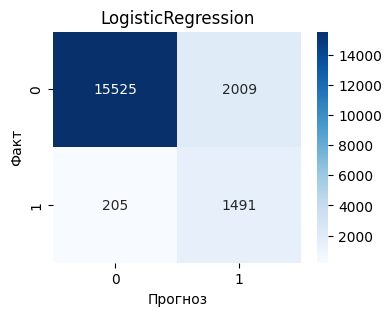

==================== RidgeClassifier ====================
              precision    recall  f1-score   support

           0      0.987     0.889     0.935     17534
           1      0.432     0.875     0.579      1696

    accuracy                          0.888     19230
   macro avg      0.709     0.882     0.757     19230
weighted avg      0.938     0.888     0.904     19230



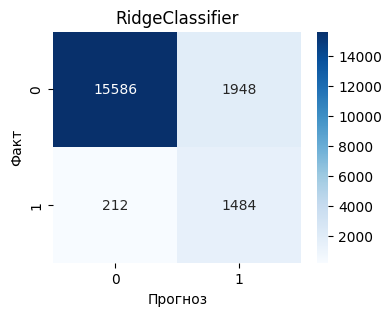

==================== SGDClassifier ====================
              precision    recall  f1-score   support

           0      0.990     0.856     0.918     17534
           1      0.379     0.909     0.535      1696

    accuracy                          0.861     19230
   macro avg      0.684     0.882     0.726     19230
weighted avg      0.936     0.861     0.884     19230



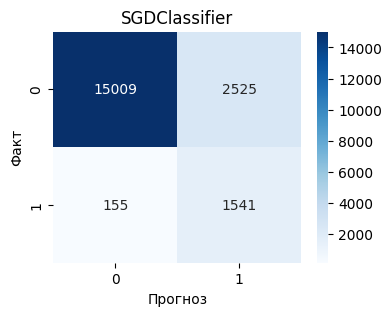

==================== SVC ====================
              precision    recall  f1-score   support

           0      0.989     0.884     0.934     17534
           1      0.429     0.898     0.581      1696

    accuracy                          0.886     19230
   macro avg      0.709     0.891     0.757     19230
weighted avg      0.940     0.886     0.903     19230



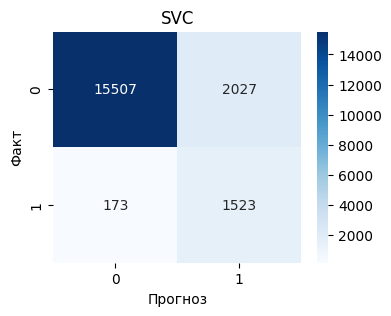

In [31]:
# SVC на всіх 140 тис. рядках вчиться дуже довго, тому для нього беремо 20 000 випадкових рядків
rng = np.random.RandomState(42)
svc_idx = rng.choice(len(X_train_bal), 20000, replace=False)

for name, model in models.items():
    if name == "SVC":
        model.fit(X_train_bal[svc_idx], y_train_bal.iloc[svc_idx])
    else:
        model.fit(X_train_bal, y_train_bal)
    y_pred = model.predict(X_test_scaled)

    print("=" * 20, name, "=" * 20)
    print(classification_report(y_test, y_pred, digits=3))

    plt.figure(figsize=(4, 3))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
    plt.title(name)
    plt.xlabel("Прогноз")
    plt.ylabel("Факт")
    plt.show()

**Висновок:** всі чотири моделі дали схожий результат. Для класу 1 recall близько 0.88-0.91, тобто моделі знаходять майже 90% хворих, але precision тільки 0.38-0.43, тобто багато здорових людей вони помилково відносять до хворих (це видно в матрицях плутанини). F1 для класу 1 близько 0.53-0.58: найкращий у SVC (0.581) і RidgeClassifier (0.579), найгірший у SGDClassifier (0.535).

Таке співвідношення через SMOTE: після балансування моделі частіше передбачають клас 1.

Оптимізувати гіперпараметри


In [32]:
param_grids = {
    "LogisticRegression": {"model__C": [0.01, 0.1, 1, 10], "model__solver": ["lbfgs", "liblinear"]},
    "RidgeClassifier": {"model__alpha": [0.1, 1, 10, 100]},
    "SGDClassifier": {"model__loss": ["hinge", "log_loss", "modified_huber"], "model__penalty": ["l2", "l1", "elasticnet"]},
    "SVC": {"model__C": [0.1, 1, 10], "model__kernel": ["rbf", "linear"]},
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [33]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [34]:
best_models = {}
best_scores = {}

# для SVC пошук робимо на 10 000 рядків train, бо на всіх даних це дуже довго
X_svc, _, y_svc, _ = train_test_split(X_train, y_train, train_size=10000, random_state=42, stratify=y_train)

for name, model in models.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", model),
    ])
    search = HalvingGridSearchCV(pipe, param_grids[name], cv=3, scoring="f1",
                                 min_resources=300, random_state=42, n_jobs=-1)
    if name == "SVC":
        search.fit(X_svc, y_svc)
    else:
        search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print("=" * 20, name, "=" * 20)
    print("Найкращі параметри:", search.best_params_)
    print("F1 на кросвалідації:", round(search.best_score_, 4))
    print("Рядків на кожному кроці пошуку:", search.n_resources_)
    print(classification_report(y_test, search.predict(X_test), digits=3))

==================== LogisticRegression ====================
Найкращі параметри: {'model__C': 1, 'model__solver': 'lbfgs'}
F1 на кросвалідації: 0.6098
Рядків на кожному кроці пошуку: [300, 900]
              precision    recall  f1-score   support

           0      0.987     0.885     0.933     17534
           1      0.426     0.879     0.574      1696

    accuracy                          0.885     19230
   macro avg      0.706     0.882     0.754     19230
weighted avg      0.937     0.885     0.902     19230

==================== RidgeClassifier ====================
Найкращі параметри: {'model__alpha': 100}
F1 на кросвалідації: 0.6587
Рядків на кожному кроці пошуку: [300, 900]
              precision    recall  f1-score   support

           0      0.987     0.889     0.935     17534
           1      0.432     0.875     0.579      1696

    accuracy                          0.888     19230
   macro avg      0.709     0.882     0.757     19230
weighted avg      0.938     0.888   

Після підбору параметрів результати на тесті майже не змінились, F1 для класу 1 близько 0.57-0.58. F1 на кросвалідації вийшов вищим, ніж на тесті, бо HalvingGridSearchCV на останньому кроці перевіряє моделі не на всіх даних, а на невеликій частині (кількість рядків видно вище).

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [35]:
print("F1 на кросвалідації:")
for name, score in sorted(best_scores.items(), key=lambda x: x[1], reverse=True):
    print(f"{name}: {score:.4f}")

best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]
print()
print("Найкраща модель:", best_name, "| F1 =", round(best_scores[best_name], 4))

F1 на кросвалідації:
RidgeClassifier: 0.6587
LogisticRegression: 0.6098
SGDClassifier: 0.6059
SVC: 0.5242

Найкраща модель: RidgeClassifier | F1 = 0.6587


In [36]:
sample_idx = X_test.sample(10, random_state=42).index

result = pd.DataFrame({
    "Індекс": sample_idx,
    "Істинний клас": y_test.loc[sample_idx].values,
    "Передбачений клас": best_model.predict(X_test.loc[sample_idx]),
})
result

,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

1. Дисбаланс великий: хворих на діабет тільки 8,5% (після видалення 3854 дублікатів 8,8%). Кореляція на train показала, що з діабетом найбільше пов'язані рівень глюкози і HbA1c, сильно корельованих ознак немає, тому нічого не видаляли. Викиди є в bmi, глюкозі і HbA1c, але ми їх залишили, бо вони можуть бути важливими для діагнозу.
2. Найкращий F1 для класу 1 на тесті дали SVC (0.581) і RidgeClassifier (0.579), найкращий recall у SGDClassifier (0.909), але в нього найгірший precision. За кросвалідацією обрали RidgeClassifier (F1 близько 0.66).
3. Оптимальні параметри: LogisticRegression C=1, solver lbfgs; RidgeClassifier alpha=100; SGDClassifier loss log_loss, penalty l2; SVC C=0.1, kernel linear. У матрицях плутанини основна помилка у всіх моделей одна: багато здорових людей потрапляють у клас 1 (близько 2000-2500 хибних тривог), а хворих пропускають мало (150-200 з 1696).
4. Тестові дані відкладаємо, щоб чесно перевірити модель на даних, яких вона не бачила. Якщо рахувати масштабування або SMOTE на всіх даних, то інформація з test потрапить у навчання і оцінка вийде завищеною. Тому scaler і SMOTE навчаємо тільки на train, а test не балансуємо, бо в реальності хворих теж мало.